In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("/content/drive/MyDrive/THE_MOON/data/raw/PSI-159_Experimental table_CFI-G_Inverse Flames.csv")



In [4]:
df.head(5)

,Flame Type,Day,Fuel,Test,Xf before test,Xf after test,approx p (bar),XO2,HC burnrate (mg/s),O2 flow rate (mg/s),TFP,Tad (K),Zst,Hot ignition,burn time (sec),Self -ext or flow term,Peak burner Temp (C),Peak burner temp (K),Color,Comments
0,Inverse,1.0,ethane,21196 A1,0.298100,0.298100,1.1000,0.210,1.5,5.590000,No,2120.000000,0.166500,No,0.0,-,27.1,300.25,-,Failed to ignite
1,Inverse,1.0,ethane,21196 A2,0.298100,0.295425,1.1000,0.210,1.5,5.590000,No,2120.000000,0.166500,Yes,35.0,FT,162.9,436.05,yellow,NaN
2,Inverse,1.0,ethane,21196 F1,0.295425,0.291765,1.1033,0.150,1.5,5.586754,No,1786.994366,0.126728,Yes,36.0,FT,118.5,391.65,blue,Not spherical shape
3,Inverse,1.0,ethane,21196 H1,0.291765,0.291765,1.1033,0.120,1.5,5.586754,No,1567.030825,0.105557,No,0.0,-,26.7,299.85,-,Not ignited
4,Inverse,1.0,ethane,21196 J1,0.291765,0.291654,1.1033,0.135,1.5,5.586754,No,1680.718299,0.116988,flash,1.0,SE,27.8,300.95,-,Not lasted long


In [5]:
df.shape

(1015, 20)

In [6]:

print(df.columns.tolist())
print(df.dtypes)
print(df['Fuel'].unique())
print(df['Hot ignition'].unique())
print(df['Color'].unique())


['Flame Type', 'Day', 'Fuel', 'Test', 'Xf  before test', 'Xf  after test', 'approx p (bar)', 'XO2', 'HC burnrate (mg/s)', 'O2 flow rate (mg/s)', 'TFP', 'Tad (K)', 'Zst', 'Hot ignition', 'burn time (sec)', 'Self -ext or flow term', 'Peak burner Temp (C)', 'Peak burner temp (K)', 'Color', 'Comments']
Flame Type                 object
Day                       float64
Fuel                       object
Test                       object
Xf  before test           float64
Xf  after test            float64
approx p (bar)            float64
XO2                       float64
HC burnrate (mg/s)        float64
O2 flow rate (mg/s)       float64
TFP                        object
Tad (K)                   float64
Zst                       float64
Hot ignition               object
burn time (sec)           float64
Self -ext or flow term     object
Peak burner Temp (C)       object
Peak burner temp (K)       object
Color                      object
Comments                   object
dtype: object
['etha

In [7]:
print(df.isna().sum())

(df.isna().mean() * 100).round(2)

Flame Type                861
Day                       861
Fuel                      861
Test                      861
Xf  before test           861
Xf  after test            861
approx p (bar)            861
XO2                       861
HC burnrate (mg/s)        861
O2 flow rate (mg/s)       861
TFP                       861
Tad (K)                   861
Zst                       861
Hot ignition              861
burn time (sec)           861
Self -ext or flow term    861
Peak burner Temp (C)      862
Peak burner temp (K)      861
Color                     871
Comments                  976
dtype: int64


,0
Flame Type,84.83
Day,84.83
Fuel,84.83
Test,84.83
Xf before test,84.83
Xf after test,84.83
approx p (bar),84.83
XO2,84.83
HC burnrate (mg/s),84.83
O2 flow rate (mg/s),84.83


In [8]:
print(df.notna().all(axis=1).sum())
print(df.isna().all(axis=1).sum())
print(df.head(10))
print(df.tail(10))

38
861
  Flame Type  Day    Fuel      Test  Xf  before test  Xf  after test  \
0    Inverse  1.0  ethane  21196 A1         0.298100        0.298100   
1    Inverse  1.0  ethane  21196 A2         0.298100        0.295425   
2    Inverse  1.0  ethane  21196 F1         0.295425        0.291765   
3    Inverse  1.0  ethane  21196 H1         0.291765        0.291765   
4    Inverse  1.0  ethane  21196 J1         0.291765        0.291654   
5    Inverse  1.0  ethane  21196 F2         0.291654        0.288336   
6    Inverse  1.0  ethane  21196 F3         0.288336        0.288310   
7    Inverse  1.0  ethane  21196 F4         0.288310        0.288273   
8    Inverse  1.0  ethane  21196 F5         0.288273        0.288109   
9    Inverse  1.0  ethane  21196 F6         0.288109        0.284829   

   approx p (bar)    XO2  HC burnrate (mg/s)  O2 flow rate (mg/s) TFP  \
0          1.1000  0.210              1.5000             5.590000  No   
1          1.1000  0.210              1.5000          

In [9]:
df_clean = df.dropna(how='all').copy()

print("Original shape:", df.shape)
print("After removing completely empty rows:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isna().sum())

Original shape: (1015, 20)
After removing completely empty rows: (154, 20)

Remaining missing values:
Flame Type                  0
Day                         0
Fuel                        0
Test                        0
Xf  before test             0
Xf  after test              0
approx p (bar)              0
XO2                         0
HC burnrate (mg/s)          0
O2 flow rate (mg/s)         0
TFP                         0
Tad (K)                     0
Zst                         0
Hot ignition                0
burn time (sec)             0
Self -ext or flow term      0
Peak burner Temp (C)        1
Peak burner temp (K)        0
Color                      10
Comments                  115
dtype: int64


In [10]:
print('missing celsius temp: \n',df_clean[df_clean['Peak burner Temp (C)'].isna()])

print('missing color: \n', df_clean[df_clean['Color'].isna()]
    [['Test', 'Fuel', 'Hot ignition', 'burn time (sec)', 'Peak burner temp (K)', 'Comments']])



missing celsius temp: 
     Flame Type   Day    Fuel      Test  Xf  before test  Xf  after test  \
129    inverse  10.0  butane  21265 H3         0.056479        0.055626   

     approx p (bar)  XO2  HC burnrate (mg/s)  O2 flow rate (mg/s) TFP  \
129          3.3099  0.4                 2.5             8.946671  No   

         Tad (K)       Zst Hot ignition  burn time (sec)  \
129  2203.074582  0.522328          Yes            107.0   

    Self -ext or flow term Peak burner Temp (C) Peak burner temp (K) Color  \
129                     FT                  NaN               273.15  Blue   

    Comments  
129      NaN  
missing color: 
          Test     Fuel Hot ignition  burn time (sec) Peak burner temp (K)  \
82   21235 C1  propane          Yes             66.0               654.65   
83   21235 F1  propane          Yes             66.0               520.05   
84   21235 F2  propane           No              0.0               299.15   
85   21235 H1  propane          Yes          

In [11]:
df_clean[df_clean['Peak burner Temp (C)'].isna()]

,Flame Type,Day,Fuel,Test,Xf before test,Xf after test,approx p (bar),XO2,HC burnrate (mg/s),O2 flow rate (mg/s),TFP,Tad (K),Zst,Hot ignition,burn time (sec),Self -ext or flow term,Peak burner Temp (C),Peak burner temp (K),Color,Comments
129,inverse,10.0,butane,21265 H3,0.056479,0.055626,3.3099,0.4,2.5,8.946671,No,2203.074582,0.522328,Yes,107.0,FT,NaN,273.15,Blue,NaN


In [12]:
print('missing comments: ',df_clean[df_clean['Comments'].isna()]
    [['Test', 'Hot ignition', 'burn time (sec)', 'Color']].head(10))

missing comments:            Test Hot ignition  burn time (sec)   Color
1     21196 A2          Yes             35.0  yellow
5     21196 F2          Yes             66.0    blue
12    21196 L2          Yes             63.0    blue
14    21196 M2          Yes             66.0    blue
15  21196 M2_1          Yes             64.0    blue
18    21202 A3          Yes              3.5    blue
19    21202 A4          Yes              5.0    blue
20    21202 H1          Yes             28.0   limit
21    21202 H2          Yes             16.0   limit
23    21202 H4          Yes             41.0    blue


In [13]:
categorical_cols = ['Flame Type','Fuel','Hot ignition','Self -ext or flow term','TFP','Color']

for col in categorical_cols:
    print(df_clean[col].value_counts(dropna=False))

Flame Type
inverse    90
Inverse    64
Name: count, dtype: int64
Fuel
butane     58
ethane     53
propane    43
Name: count, dtype: int64
Hot ignition
Yes      114
yes       17
No        13
flash      8
no         2
Name: count, dtype: int64
Self -ext or flow term
SE    81
FT    58
-     15
Name: count, dtype: int64
TFP
No     142
Yes     12
Name: count, dtype: int64
Color
blue                47
limit               29
-                   24
Yellow-Blue         20
Blue                12
NaN                 10
yellow               6
Yellow               4
yellow then blue     2
Name: count, dtype: int64


In [14]:
df_analysis = df_clean.copy()

In [15]:
cols_to_standardize = ['Flame Type','Fuel','Hot ignition','Self -ext or flow term','TFP','Color']

for col in cols_to_standardize:
    df_analysis[col] =df_analysis[col].apply(
        lambda x: x.strip().lower() if isinstance(x,str) else x
    )

In [16]:
for col in cols_to_standardize:
    print(df_analysis[col].value_counts(dropna=False))

Flame Type
inverse    154
Name: count, dtype: int64
Fuel
butane     58
ethane     53
propane    43
Name: count, dtype: int64
Hot ignition
yes      131
no        15
flash      8
Name: count, dtype: int64
Self -ext or flow term
se    81
ft    58
-     15
Name: count, dtype: int64
TFP
no     142
yes     12
Name: count, dtype: int64
Color
blue                59
limit               29
-                   24
yellow-blue         20
yellow              10
NaN                 10
yellow then blue     2
Name: count, dtype: int64


In [17]:
df_analysis['Experiment ID'] = (df_analysis['Test'].str.extract(r'^(\d+)'))

print("Unique experiment IDs: ",df_analysis['Experiment ID'].nunique())
print("Record Per Experiment: ", df_analysis['Experiment ID'].value_counts().sort_index())

Unique experiment IDs:  12
Record Per Experiment:  Experiment ID
21196    16
21202    12
21209    12
21216    13
21222    10
21228    17
21235    10
21242     6
21256    17
21265    17
21270    10
21277    14
Name: count, dtype: int64


In [18]:
for exp_id, group in df_analysis.groupby('Experiment ID'):
    print(f"Experiment ID: {exp_id}")
    print(group['Test'].tolist())

Experiment ID: 21196
['21196 A1', '21196 A2', '21196 F1', '21196 H1', '21196 J1', '21196 F2', '21196 F3', '21196 F4', '21196 F5', '21196 F6', '21196 K1', '21196 L1', '21196 L2', '21196 M1', '21196 M2', '21196 M2_1']
Experiment ID: 21202
['21202 A1', '21202 A2', '21202 A3', '21202 A4', '21202 H1', '21202 H2', '21202 H3', '21202 H4', '21202 J1', '21202 K1', '21202 K2', '21202 L1']
Experiment ID: 21209
['21209 A1', '21209 A2', '21209 A3', '21209 B1', '21209 A4', '21209 H1', '21209 J1', '21209 F1', '21209 F2', '21209 F3', '21209 B2', '21209 K1']
Experiment ID: 21216
['21216 A1', '21216 A2', '21216 A3', '21216 A4', '21216 A5', '21216 A6', '21216 B1', '21216 C1', '21216 F1', '21216 H1', '21216 H2', '21216 J1', '21216 K1']
Experiment ID: 21222
['21222 A1', '21222 A2', '21222 A3', '21222 A4', '21222 A5', '21222 B1', '21222 C1', '21222 C2', '21222 F1', '21222 F2']
Experiment ID: 21228
['21228 A1', '21228 A2', '21228 A3', '21228 A4', '21228 B1', '21228 C1', '21228 C2', '21228 C3', '21228 C4', '2

In [19]:
cols = [
    'Test',
    'Fuel',
    'Xf  before test',
    'Xf  after test',
    'approx p (bar)',
    'XO2',
    'HC burnrate (mg/s)',
    'O2 flow rate (mg/s)',
    'Tad (K)',
    'Hot ignition',
    'burn time (sec)',
    'Self -ext or flow term'
]

df_analysis.loc[
    df_analysis['Experiment ID'] == '21256',
    cols
].sort_values(by='Test')

,Test,Fuel,Xf before test,Xf after test,approx p (bar),XO2,HC burnrate (mg/s),O2 flow rate (mg/s),Tad (K),Hot ignition,burn time (sec),Self -ext or flow term
96,21256 A1,butane,0.088100,0.088041,2.2066,0.85,1.500,5.368002,2678.571274,yes,9.0,se
97,21256 A2,butane,0.088041,0.087994,2.2066,0.85,1.000,3.578668,2678.326663,yes,11.0,se
98,21256 A3,butane,0.087994,0.087970,2.2066,0.85,0.500,1.789334,2678.127192,yes,11.0,se
99,21256 A4,butane,0.087970,0.087962,2.2066,0.85,0.375,1.342001,2678.027398,yes,5.0,se
100,21256 A5,butane,0.087962,0.087864,2.2066,0.85,2.500,8.946671,2677.993369,yes,9.0,se
103,21256 B1,butane,0.086880,0.086796,2.2066,0.85,1.500,5.368002,2673.425067,yes,13.0,se
101,21256 C1,butane,0.087864,0.087790,2.2066,0.50,1.500,5.368002,2509.345147,yes,9.0,se
104,21256 C2,butane,0.086796,0.086771,2.2066,0.50,0.500,1.789334,2504.933499,yes,9.0,se
102,21256 F1,butane,0.087790,0.086880,2.2066,0.21,1.500,5.368002,1956.107065,yes,66.0,ft
105,21256 H1,butane,0.070000,0.069959,2.2066,0.85,1.500,5.368002,2585.922171,yes,7.0,se


In [20]:
df_analysis['Test_group'] = (df_analysis['Test'].str.extract(r'^\d+\s*([A-Z]+)'))

summary = (df_analysis.groupby(['Experiment ID','Test_group'])
        .agg(
            tests = ('Test','count'),
            fuels = ('Fuel','nunique'),
            oxy_levels = ('XO2','nunique'),
            pressures = ('approx p (bar)','nunique'),
            burn_rates = ('HC burnrate (mg/s)','nunique')
        ))
print(summary.to_string())

                          tests  fuels  oxy_levels  pressures  burn_rates
Experiment ID Test_group                                                 
21196         A               2      1           1          1           1
              F               6      1           1          1           5
              H               1      1           1          1           1
              J               1      1           1          1           1
              K               1      1           1          1           1
              L               2      1           1          1           1
              M               3      1           1          1           2
21202         A               4      1           1          1           4
              H               4      1           1          1           4
              J               1      1           1          1           1
              K               2      1           1          1           2
              L               1      1

In [21]:
oxy_summary = (df_analysis.groupby('XO2')
            .agg(
                test_count = ('Test','count'),
                mean_tad = ('Tad (K)','mean'),
                min_tad = ('Tad (K)','min'),
                max_tad = ('Tad (K)','max'),
                mean_burn_time = ('burn time (sec)','mean'))
            .round(2))

print(oxy_summary)

       test_count  mean_tad  min_tad  max_tad  mean_burn_time
XO2                                                          
0.120           1   1567.03  1567.03  1567.03            0.00
0.135           1   1680.72  1680.72  1680.72            1.00
0.150           7   1783.90  1781.61  1786.99           24.57
0.180           2   1919.65  1885.14  1954.15           15.00
0.190           1   2006.68  2006.68  2006.68           66.00
0.210          27   1989.46  1779.77  2210.03           26.50
0.300           9   2437.35  2339.78  2507.22           30.89
0.400           3   2207.02  2203.07  2209.00           58.00
0.450           1   2260.71  2260.71  2260.71            5.00
0.500          22   2467.80  2283.99  2788.03           24.00
0.700           1   2427.15  2427.15  2427.15            6.00
0.850          79   2632.70  2077.25  2978.37           31.50


Text(0.5, 1.0, 'XO2 vs Tad')

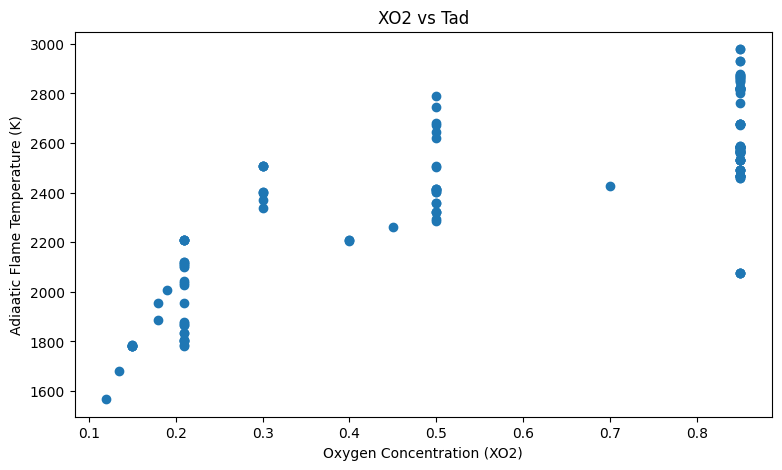

In [22]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(9,5))

plt.scatter(df_analysis['XO2'],df_analysis['Tad (K)'])

plt.xlabel('Oxygen Concentration (XO2)')
plt.ylabel('Adiaatic Flame Temperature (K)')
plt.title('XO2 vs Tad')

In [23]:
fuel_summary = (df_analysis.groupby('Fuel')
                .agg(
                    test_count = ('Test','count'),
                    mean_tad =('Tad (K)','mean'),
                    min_tad = ('Tad (K)','min'),
                    max_tad = ('Tad (K)','max'))
                .round(2))

print(fuel_summary)

         test_count  mean_tad  min_tad  max_tad
Fuel                                           
butane           58   2525.09  1801.00  2977.82
ethane           53   2270.63  1567.03  2820.98
propane          43   2419.02  1834.52  2978.37


In [24]:
df_analysis.info()

<class 'pandas.core.frame.DataFrame'>
Index: 154 entries, 0 to 153
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Flame Type              154 non-null    object 
 1   Day                     154 non-null    float64
 2   Fuel                    154 non-null    object 
 3   Test                    154 non-null    object 
 4   Xf  before test         154 non-null    float64
 5   Xf  after test          154 non-null    float64
 6   approx p (bar)          154 non-null    float64
 7   XO2                     154 non-null    float64
 8   HC burnrate (mg/s)      154 non-null    float64
 9   O2 flow rate (mg/s)     154 non-null    float64
 10  TFP                     154 non-null    object 
 11  Tad (K)                 154 non-null    float64
 12  Zst                     154 non-null    float64
 13  Hot ignition            154 non-null    object 
 14  burn time (sec)         154 non-null    float64

In [25]:
print(df_analysis['Peak burner Temp (C)'].unique())
print(df_analysis['Peak burner temp (K)'].unique())

['27.1' '162.9' '118.5' '26.7' '27.8' '169.2' '39.9' '66.1' '28.4' '167.3'
 '63.5' '122.9' '273.7' '136.4' '515.2' '515.3' '26.5' '62.3' '50.6'
 '44.6' '214.1' '107.6' '469.1' '301.2' '327.8' '275.7' '113.4' '255.6'
 '544.1' '25.7' '300.3' '300' '419.1' '290.2' '248.4' '201.4' '213.7'
 '317.3' '514' '128.1' '160.2' '119' '100' '330.4' '59.6' '471.4' '142.9'
 '77.6' '126.5' '120.5' '99.1' '111.3' '131.4' '102.1' '148.4' '100.4'
 '178' '92.4' '118.7' '54.6' '68.3' '26.2' '88.8' '81.8' '170.3' '112.1'
 '62.4' '147.2' '62' '142.3' '118.3' '77.9' '182.6' '198.9' '66.6' '165.6'
 '29.7' '68.1' '364.2' '253.3' '381.5' '246.9' '26' '55.2' '181.1' '411.6'
 '400.7' '291' '651.5' '173.8' '25.6' '25.9' '-' '102' '130.7' '174.6'
 '84' '64.1' '131.5' '111.7' '154.7' '79.2' '100.6' '75.4' '68.9' '42.7'
 '75.5' '75.8' '81.7' '74.2' '91.3' '69.2' '38.5' '45.5' '38.4' '124.7'
 '34.1' '135' '56.9' '43.7' nan '328.9' '240.9' '460.1' '433.3' '210.4'
 '244.3' '454.6' '352.5' '217' '260.4' '529.3' '462.1' '25

In [26]:
for col in ['Peak burner Temp (C)', 'Peak burner temp (K)']:
    numeric_values = pd.to_numeric(df_analysis[col], errors='coerce')

    invalid = df_analysis[
        numeric_values.isna() & df_analysis[col].notna()
    ]

    print(f"\n{col}")
    print(invalid[['Test', col]])


Peak burner Temp (C)
        Test Peak burner Temp (C)
94  21242 F4                    -
95  21242 P2                    -

Peak burner temp (K)
        Test Peak burner temp (K)
94  21242 F4              #VALUE!
95  21242 P2              #VALUE!


In [27]:
temperature_cols = [
    'Peak burner Temp (C)',
    'Peak burner temp (K)'
]

for col in temperature_cols:
    df_analysis[col] = pd.to_numeric(
        df_analysis[col].replace('-', np.nan),
        errors='coerce'
    )

In [28]:
df_analysis[temperature_cols].info()

print(df_analysis[temperature_cols].isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 154 entries, 0 to 153
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Peak burner Temp (C)  151 non-null    float64
 1   Peak burner temp (K)  152 non-null    float64
dtypes: float64(2)
memory usage: 3.6 KB
Peak burner Temp (C)    3
Peak burner temp (K)    2
dtype: int64


In [29]:
valid = df_analysis[
    ['Peak burner Temp (C)', 'Peak burner temp (K)']
].dropna()

valid['Calculated_K'] = valid['Peak burner Temp (C)'] + 273.15

valid['Difference'] = (
    valid['Peak burner temp (K)'] - valid['Calculated_K']
)

print(valid['Difference'].describe())

count    1.510000e+02
mean     2.446902e-14
std      3.504674e-14
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      5.684342e-14
max      1.136868e-13
Name: Difference, dtype: float64


In [30]:
missing_color = df_analysis[df_analysis['Color'].isna()]

print(missing_color[
    ['Test', 'Fuel', 'XO2', 'Hot ignition',
    'burn time (sec)', 'Self -ext or flow term']
].to_string(index=False))

    Test    Fuel  XO2 Hot ignition  burn time (sec) Self -ext or flow term
21235 C1 propane 0.50          yes             66.0                     ft
21235 F1 propane 0.21          yes             66.0                     ft
21235 F2 propane 0.21           no              0.0                      -
21235 H1 propane 0.18          yes              4.0                     se
21235 J1 propane 0.19          yes             66.0                     ft
21235 B1 propane 0.85          yes            152.0                     ft
21235 K1 propane 0.85          yes             66.0                     ft
21235 L1 propane 0.85          yes            127.0                     ft
21256 M1  butane 0.21          yes              1.0                     se
21256 J1  butane 0.85          yes              7.0                     se


In [31]:
categorical_cols = [
    'Flame Type',
    'Fuel',
    'TFP',
    'Hot ignition',
    'Self -ext or flow term',
    'Color'
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_analysis[col].value_counts(dropna=False))


--- Flame Type ---
Flame Type
inverse    154
Name: count, dtype: int64

--- Fuel ---
Fuel
butane     58
ethane     53
propane    43
Name: count, dtype: int64

--- TFP ---
TFP
no     142
yes     12
Name: count, dtype: int64

--- Hot ignition ---
Hot ignition
yes      131
no        15
flash      8
Name: count, dtype: int64

--- Self -ext or flow term ---
Self -ext or flow term
se    81
ft    58
-     15
Name: count, dtype: int64

--- Color ---
Color
blue                59
limit               29
-                   24
yellow-blue         20
yellow              10
NaN                 10
yellow then blue     2
Name: count, dtype: int64


In [32]:
df_analysis[
    df_analysis['Self -ext or flow term'] == '-'
][[
    'Test',
    'Fuel',
    'XO2',
    'Hot ignition',
    'burn time (sec)',
    'Tad (K)',
    'Color',
    'Comments'
]].to_string(index=False)

'    Test    Fuel  XO2 Hot ignition  burn time (sec)     Tad (K) Color                               Comments\n21196 A1  ethane 0.21           no              0.0 2120.000000     -                       Failed to ignite\n21196 H1  ethane 0.12           no              0.0 1567.030825     -                            Not ignited\n21202 A1  ethane 0.85           no              0.0 2077.502017     -                            No ignition\n21209 A2  ethane 0.85           no              0.0 2819.838789     -                                Aborted\n21222 F2 propane 0.21           no              0.0 1834.524346     -                            No ignition\n21235 F2 propane 0.21           no              0.0 2101.707843   NaN                                    NaN\n21242 F2 propane 0.21           no              0.0 2207.969786     - F1 was aborted, and F2 did not ignite.\n21242 F3 propane 0.21           no              0.0 2207.969786     -                                    NaN\n21242 F4 

In [33]:
df_analysis[
    df_analysis['Hot ignition'] == 'flash'
][[
    'Test',
    'Fuel',
    'XO2',
    'approx p (bar)',
    'HC burnrate (mg/s)',
    'Tad (K)',
    'burn time (sec)',
    'Self -ext or flow term',
    'Color',
    'Comments'
]].to_string(index=False)

'    Test   Fuel   XO2  approx p (bar)  HC burnrate (mg/s)     Tad (K)  burn time (sec) Self -ext or flow term Color         Comments\n21196 J1 ethane 0.135        1.103300              1.5000 1680.718299              1.0                     se     -  Not lasted long\n21196 F3 ethane 0.150        1.103300              0.3750 1783.432003              1.0                     se     - A flash and gone\n21196 F4 ethane 0.150        1.103300              0.5625 1783.419087              1.0                     se     -  Not lasted long\n21196 F5 ethane 0.150        1.103300              2.4390 1783.399711              1.0                     se     -  Not lasted long\n21196 K1 ethane 0.150        0.495382              0.7500 1781.609691              1.0                     se     -  Not lasted long\n21196 L1 ethane 0.210        0.495382              0.7500 2111.046770              1.0                     se     -  Not lasted long\n21196 M1 ethane 0.300        0.495382              0.7500 240

In [34]:
df.describe()

,Day,Xf before test,Xf after test,approx p (bar),XO2,HC burnrate (mg/s),O2 flow rate (mg/s),Tad (K),Zst,burn time (sec)
count,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000
mean,6.487013,0.156714,0.155732,1.731522,0.589123,1.351668,4.917009,2407.896862,0.455507,28.987013
std,3.559461,0.100924,0.100311,1.056863,0.286898,0.668340,2.423203,341.920229,0.196970,31.265934
min,1.000000,0.056479,0.055626,0.495382,0.120000,0.250000,0.931126,1567.030825,0.105557,0.000000
25%,3.000000,0.081672,0.081526,0.551650,0.232500,0.750000,2.793377,2204.298383,0.306815,5.000000
50%,6.000000,0.099961,0.099888,1.103300,0.850000,1.500000,5.368002,2492.967081,0.490102,15.000000
75%,10.000000,0.210363,0.204525,2.206600,0.850000,1.500000,5.586754,2612.785432,0.642064,62.250000
max,12.000000,0.428700,0.427799,3.309900,0.850000,2.500000,9.084062,2978.371796,0.783918,152.000000


In [35]:
import os

output_dir = "/content/drive/MyDrive/THE_MOON/data/processed"
os.makedirs(output_dir, exist_ok=True)

df_inverse = df_analysis.copy()

df_inverse.to_csv(f"{output_dir}/inverse_analysis.csv", index=False)